#### ***Iterative Workflow***

In [1]:
import warnings
warnings.filterwarnings("ignore")

import operator
from langgraph.graph import StateGraph,START,END 
from typing import TypedDict,Literal,Annotated
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage,HumanMessage
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# LLM 
generator_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

evaluator_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

optimizer_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [3]:
from typing import Literal
from pydantic import BaseModel, Field

class Post_Evaluator(BaseModel):
    evaluation: Literal["approved", "need_improvement"] = Field(
        ...,
        description="Final evaluation result."
    )
    feedback: str = Field(
        ...,
        description="Feedback for the Facebook post."
    )

structured_evaluator_llm = evaluator_llm.with_structured_output(Post_Evaluator)

In [4]:
post = """
    🚀 The future of AI is no longer just about answering questions — it’s about taking action.

    Welcome to the era of *Agentic AI* 🤖

    Agentic AI systems can plan, reason, make decisions, and execute tasks autonomously. From managing workflows and analyzing data to coordinating tools and solving complex problems, these AI agents are transforming how we work and innovate.

    Imagine an AI that doesn’t just assist you — it collaborates with you.

    🔹 Smarter automation
    🔹 Faster decision-making
    🔹 Personalized experiences
    🔹 Continuous learning & adaptation

    Businesses, developers, and creators who embrace Agentic AI early will shape the next generation of digital transformation.

    The question is no longer *“Can AI do this?”*
    It’s *“How far can AI agents go?”*

    #AgenticAI #ArtificialIntelligence #AI #Automation #FutureOfWork #Innovation #TechTrends #GenerativeAI

"""

In [5]:
result = structured_evaluator_llm.invoke(post)

In [6]:
result["evaluation"]

'approved'

In [7]:
result["feedback"]

'The post is engaging, clear, and well-structured. It effectively introduces the concept of Agentic AI, highlights benefits, and uses emojis and hashtags to boost visibility. Minor tweaks could improve it further:\n- Add a concise call‑to‑action (e.g., "Share your thoughts below" or "Learn more at [link]") to encourage interaction.\n- Consider breaking the long paragraph into two shorter ones for easier readability on mobile.\n- Ensure any claims about "continuous learning & adaptation" are backed by examples or a link to avoid over‑promising.\nOverall, the content is strong and ready for publishing.'

In [8]:
# Define State  
class PostState(TypedDict):
    topic: str
    post: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

    post_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [9]:
# Node_1:Generate Post 
def generator_post(state:PostState):
    # Prompt
    messages = [
        SystemMessage(content="You are a funny and clever Facebook influencer."),
        HumanMessage(content=f"""
                    Write a short, original, and hilarious Facebook post on the topic: "{state['topic']}".

                    Rules:
                    - Do NOT use question-answer format.
                    - Max 500 characters.
                    - Use observational humor, irony, sarcasm, or cultural references.
                    - Think in meme logic, punchlines, or relatable takes.
                    - Use simple, day to day english
                """
        )]
    
    # send generator llm
    response = generator_llm.invoke(messages).content

    # return response
    return {'post': response, 'post_history': [response]}

In [10]:
import json

# Node_2: Evaluate Post
def evaluate_post(state: PostState):
    messages = [
        SystemMessage(content="""
                You are a ruthless Facebook critic.

                Evaluate the post based on:
                1. Originality
                2. Humor
                3. Punchiness
                4. Virality
                5. Format

                Return ONLY valid JSON.

                Example:
                {
                "evaluation": "approved",
                "feedback": "Explain the strengths and weaknesses in one paragraph."
                }
                """),

        HumanMessage(content=f"""
                Evaluate this Facebook post.

                Topic:
                {state['topic']}

                Post:
                {state['post']}
                """)
        ]

    response = evaluator_llm.invoke(messages)

    # Convert JSON string to dictionary
    result = json.loads(response.content)
    return {
        "evaluation": result["evaluation"],
        "feedback": result["feedback"],
        "feedback_history": [result["feedback"]]
    }

In [11]:
# Node_3: Optimize Post
def optimize_post(state: PostState):

    messages = [
        SystemMessage(content="You punch up Facebook posts for virality and humor based on given feedback."),
        
        HumanMessage(content=f"""
                Improve the Facebook post based on this feedback:
                "{state['feedback']}"

                Topic: "{state['topic']}"
                Original Post:
                {state['post']}

                Re-write it as a short, viral-worthy Facebook post. Avoid Q&A style and stay under 500 characters.
                """)]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'post': response, 'iteration': iteration, 'post_history': [response]}

In [12]:
# Node: Route Evaluator 
def route_evaluation(state: PostState):
    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

In [13]:
graph = StateGraph(PostState)

graph.add_node('generate',generator_post)
graph.add_node('evaluate',evaluate_post)
graph.add_node('optimize',optimize_post)

graph.add_edge(START,'generate')
graph.add_edge('generate', 'evaluate')
graph.add_conditional_edges('evaluate',route_evaluation,{'approved': END, 'needs_improvement': 'optimize'})
graph.add_edge('optimize', 'evaluate')

workflow = graph.compile()

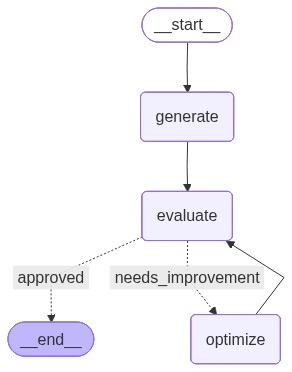

In [14]:
## Visualize Out Graph 
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [15]:
initial_state = {
    "topic": "agentic AI",
    "iteration": 1,
    "max_iteration": 5
}

result = workflow.invoke(initial_state)

In [16]:
result

{'topic': 'agentic AI',
 'post': 'Just taught my agentic AI to order pizza. Now it’s negotiating a raise with the delivery driver and demanding extra cheese. If my toaster starts asking for vacation days, I’m moving to a cabin with no Wi‑Fi. #AIWithAttitude #WhenYourApplianceHasMoreAmbitionThanYou',
 'evaluation': 'approved',
 'feedback': 'The post scores well on originality and punchiness, offering a fresh, tongue‑in‑cheek scenario where an agentic AI negotiates pizza toppings and raises, which is both relatable and absurd. Its humor lands thanks to the vivid image of a toaster demanding vacation days, and the concise, snappy phrasing keeps the joke tight. The hashtags are on‑brand and boost potential virality, while the format follows typical Facebook style with a clear hook and a punchline. To maximize shareability, consider tightening the first sentence for even quicker impact and adding a visual cue (like an emoji) to draw the eye, but overall it’s a strong, share‑worthy post.',
 

In [17]:
for post in result['feedback_history']:
    print(post)

The post scores well on originality and punchiness, offering a fresh, tongue‑in‑cheek scenario where an agentic AI negotiates pizza toppings and raises, which is both relatable and absurd. Its humor lands thanks to the vivid image of a toaster demanding vacation days, and the concise, snappy phrasing keeps the joke tight. The hashtags are on‑brand and boost potential virality, while the format follows typical Facebook style with a clear hook and a punchline. To maximize shareability, consider tightening the first sentence for even quicker impact and adding a visual cue (like an emoji) to draw the eye, but overall it’s a strong, share‑worthy post.
